# 01 - Data Preprocessing and EDA

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.cleaning import load_raw, run_cleaning
sns.set_theme(style="whitegrid")
raw = load_raw()
print(raw.shape)
raw.head()

(546123, 44)


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0.0,NaN,NaN,-0.02,1.0,0.0,17072.0
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,...,NaN,NaN,68.54,0.0,NaN,NaN,-0.02,2.0,0.0,17072.0
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,...,NaN,NaN,68.54,0.0,NaN,NaN,-0.02,3.0,0.0,17072.0
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,...,NaN,NaN,68.54,0.0,NaN,NaN,-0.02,4.0,0.0,17072.0
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,...,NaN,330.0,68.54,0.0,NaN,NaN,-0.02,5.0,0.0,17072.0


## 1. Raw data quality

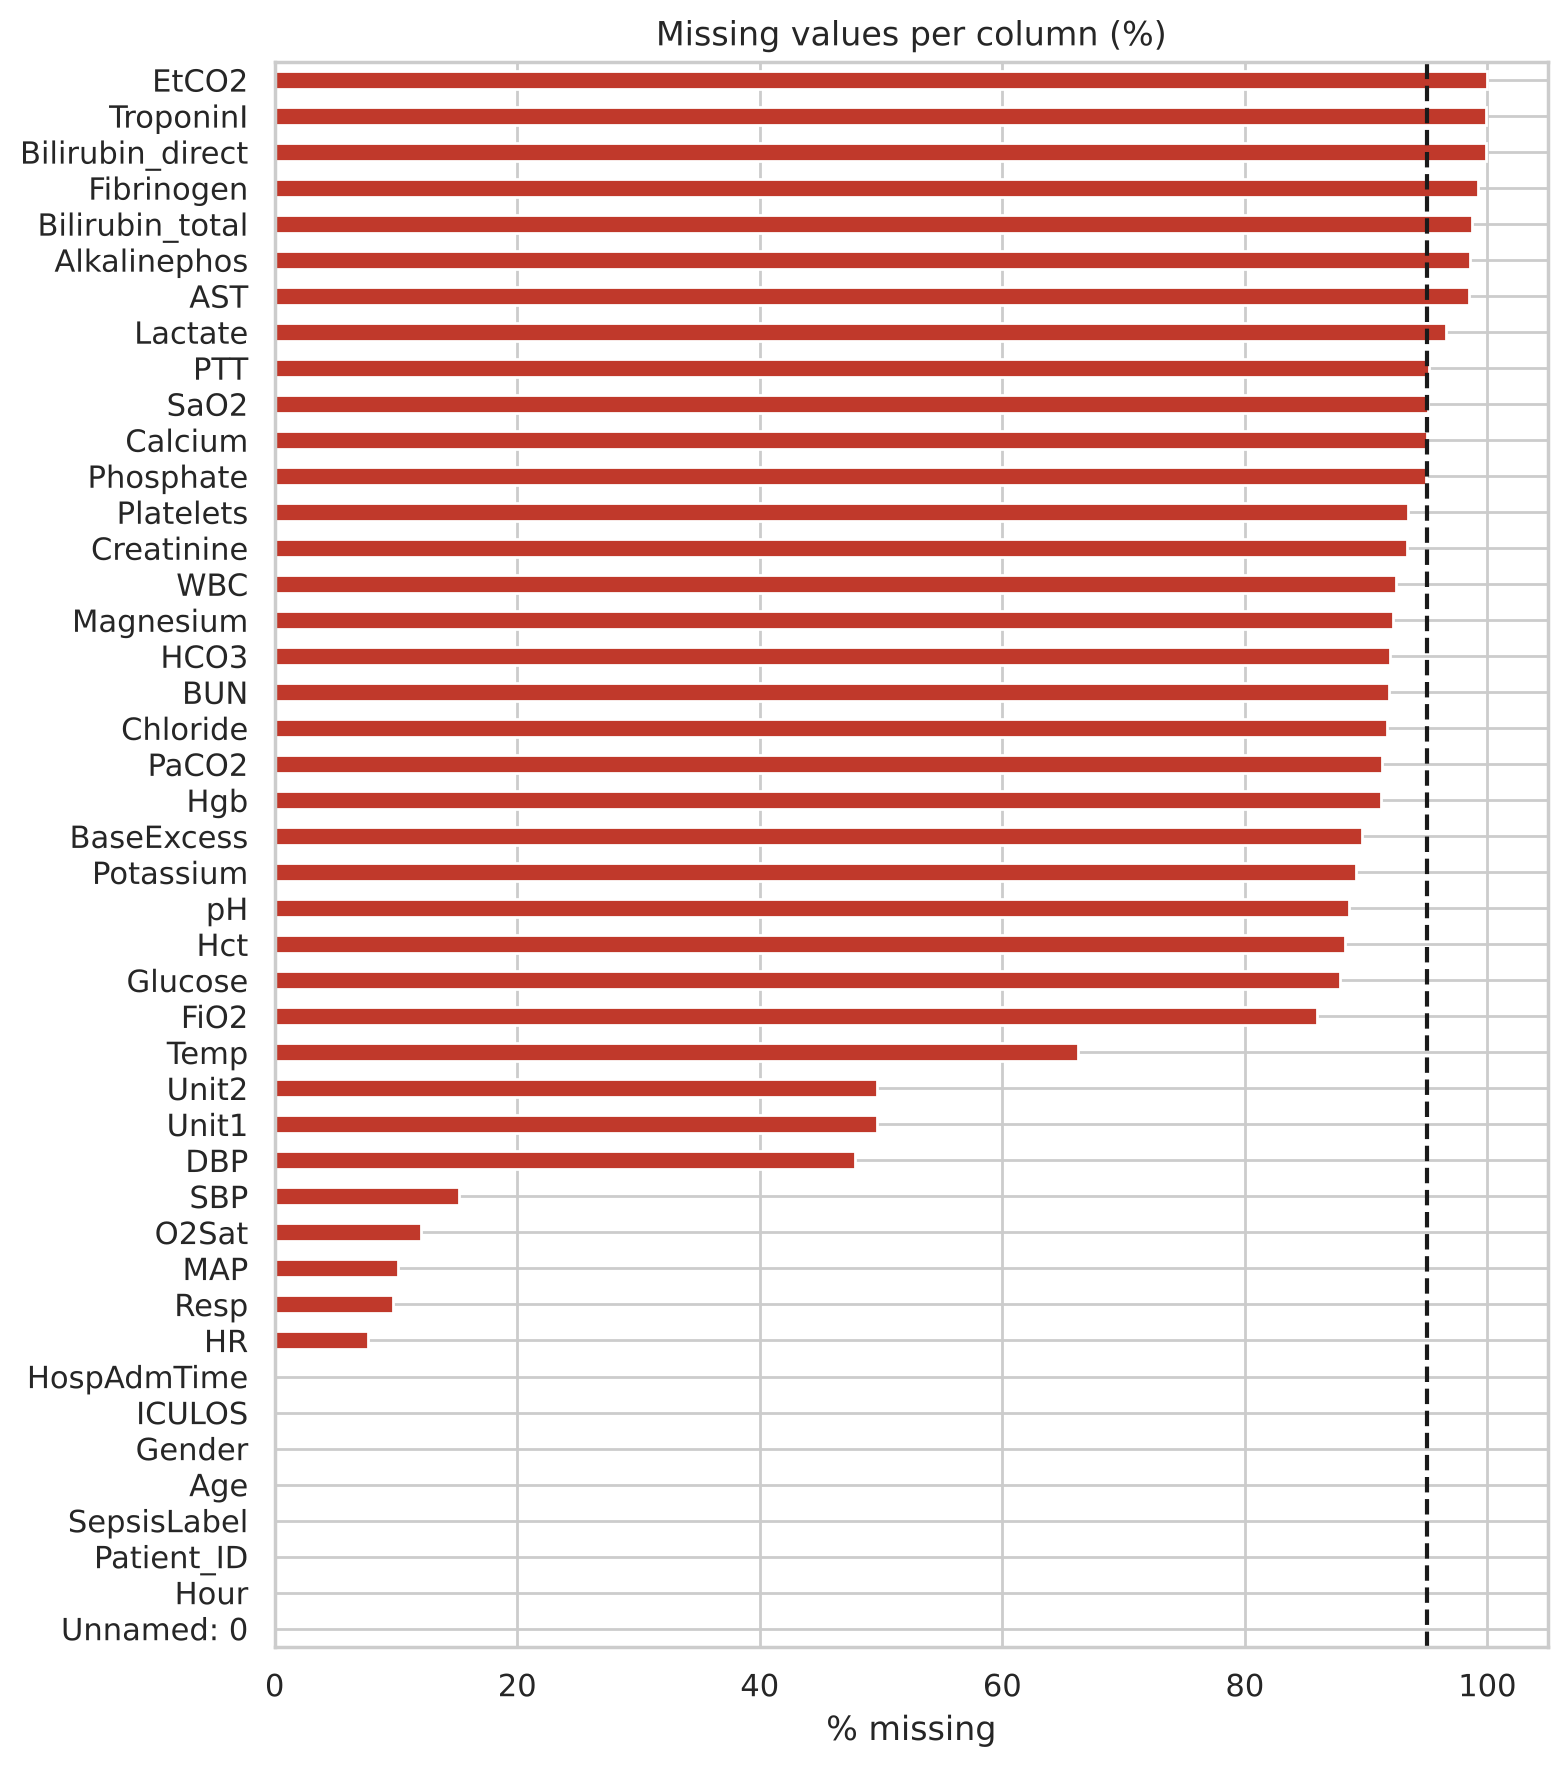

Exact duplicate rows: 0
Rows with missing Patient_ID: 1


In [2]:
miss = (raw.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 9))
miss.plot.barh(ax=ax, color="#c0392b")
ax.axvline(C.MISSING_DROP_THRESHOLD * 100, color="k", ls="--")
ax.set(title="Missing values per column (%)", xlabel="% missing")
ax.invert_yaxis(); plt.tight_layout()
plt.savefig(C.FIG_DIR / "eda_missing.png", dpi=130); plt.show()
print("Exact duplicate rows:", raw.duplicated().sum())
print("Rows with missing Patient_ID:", raw[C.GROUP].isna().sum())

## 2. Run the cleaning pipeline

In [3]:
clean = run_cleaning()
clean.shape

{'raw_rows': 546123, 'after_duplicates': 546122, 'columns_kept': 14}
split
train    384548
val       81129
test      80445
Name: count, dtype: int64


(546122, 16)

## 3. Class balance (sepsis is rare)

SepsisLabel
0.0    534272
1.0     11850
Name: count, dtype: int64 
Sepsis rows: 2.17%
Patients who got sepsis: 8.8%


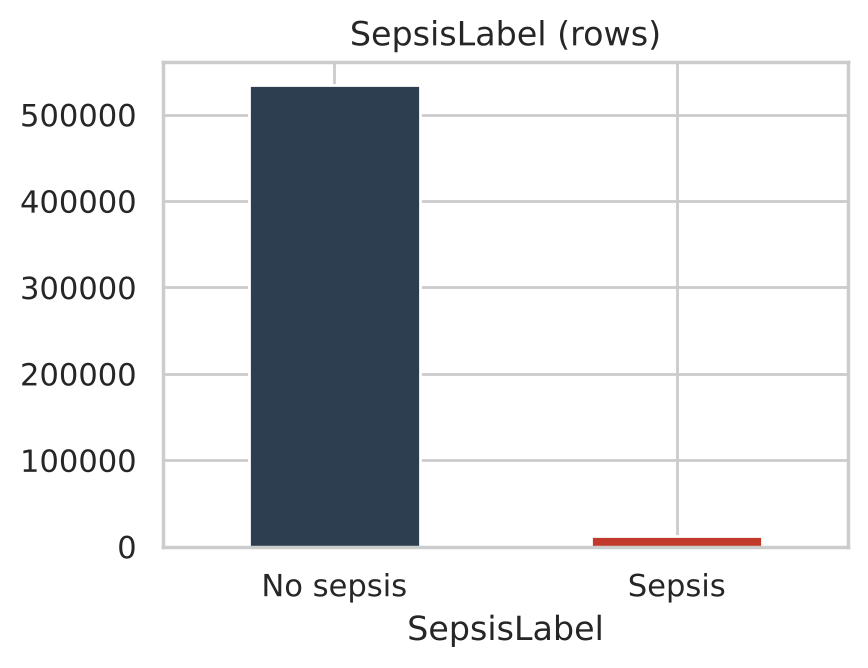

In [4]:
counts = clean[C.TARGET].value_counts()
print(counts, "\nSepsis rows: %.2f%%" % (100 * counts[1] / counts.sum()))
per_patient = clean.groupby(C.GROUP)[C.TARGET].max()
print("Patients who got sepsis: %.1f%%" % (100 * per_patient.mean()))
fig, ax = plt.subplots(figsize=(4.5, 3.5))
counts.rename({0: "No sepsis", 1: "Sepsis"}).plot.bar(ax=ax, color=["#2c3e50", "#c0392b"], rot=0)
ax.set(title="SepsisLabel (rows)"); plt.tight_layout()
plt.savefig(C.FIG_DIR / "eda_class_balance.png", dpi=130); plt.show()

## 4. Vitals and labs: sepsis vs no sepsis

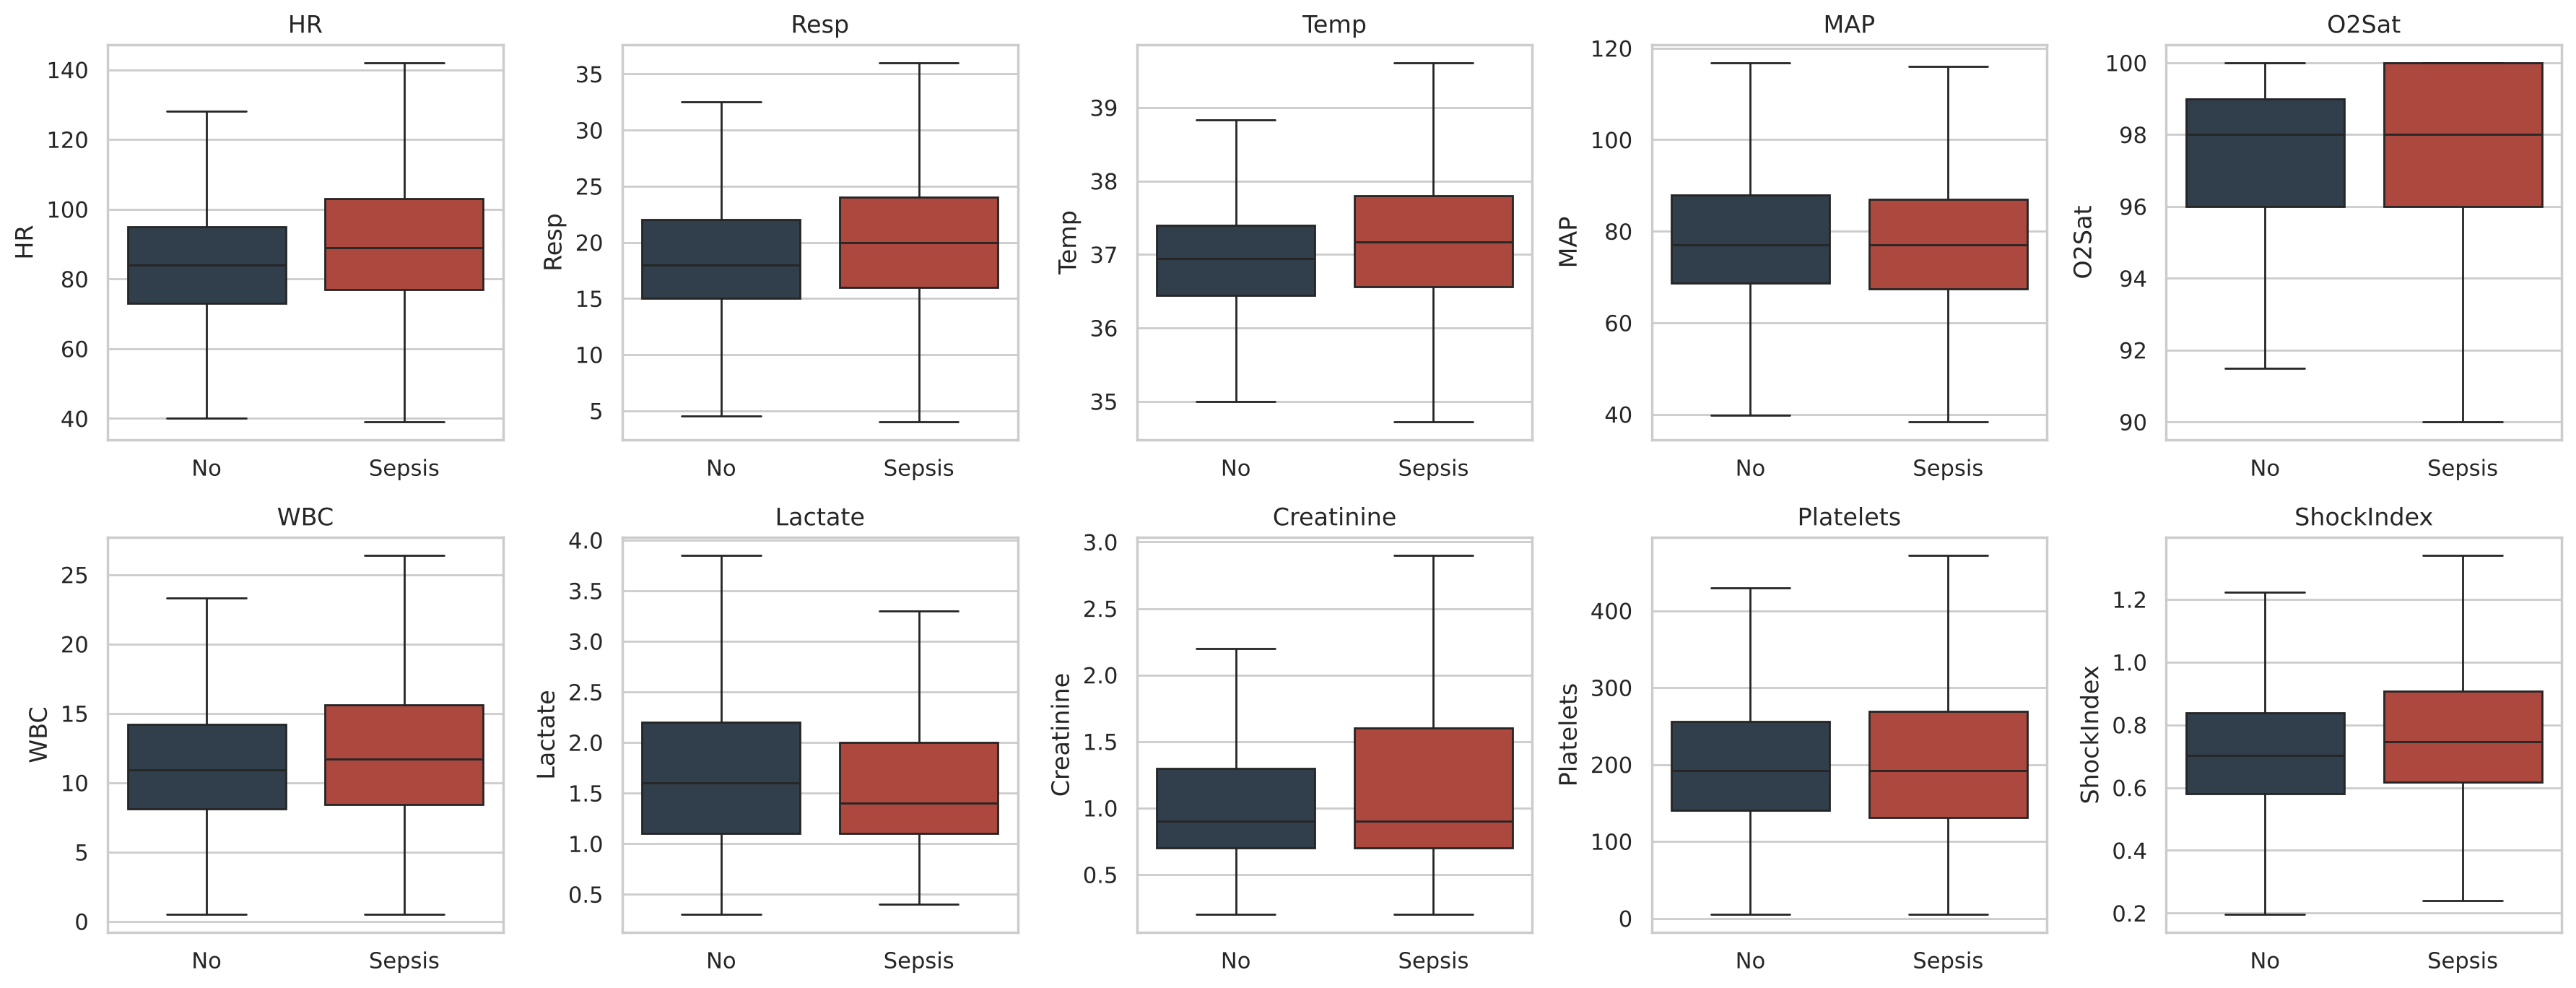

In [5]:
cols = ["HR", "Resp", "Temp", "MAP", "O2Sat", "WBC", "Lactate", "Creatinine", "Platelets", "ShockIndex"]
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(data=clean, x=C.TARGET, y=c, ax=ax, showfliers=False,
                palette=["#2c3e50", "#c0392b"])
    ax.set(title=c, xlabel="", xticklabels=["No", "Sepsis"])
plt.tight_layout(); plt.savefig(C.FIG_DIR / "eda_boxplots.png", dpi=130); plt.show()

## 5. Correlation and ICU stay

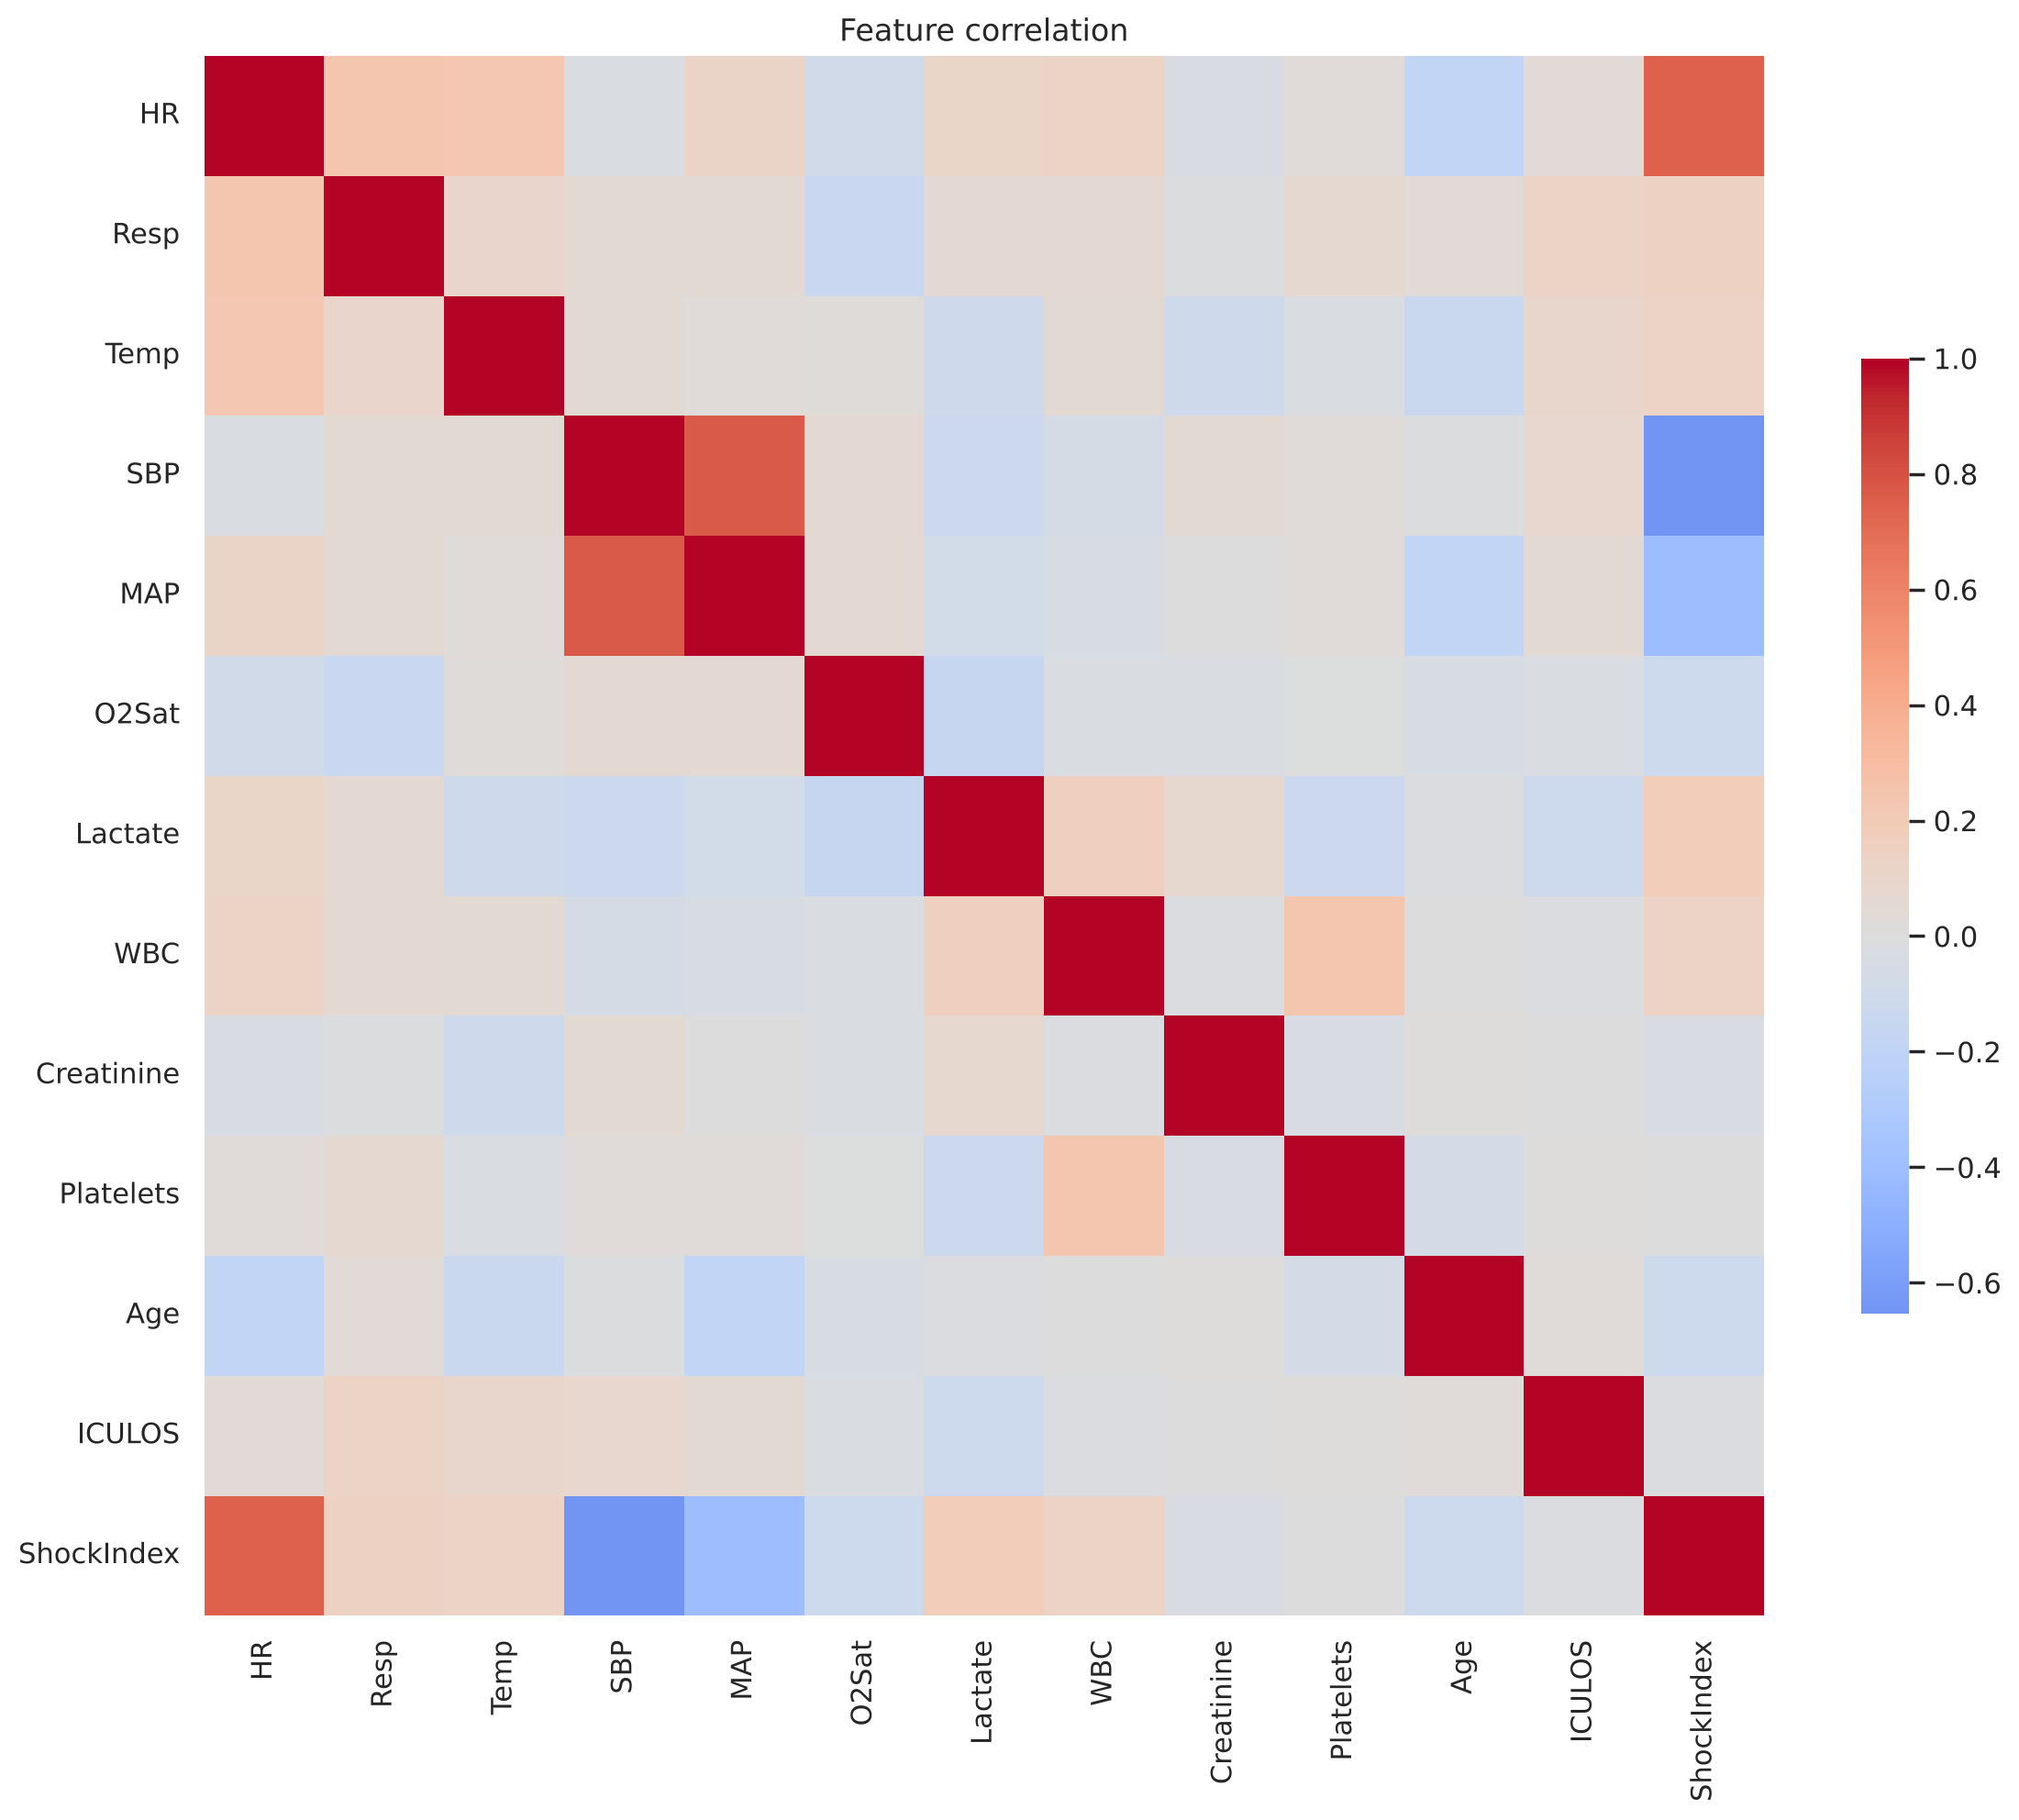

Platelets     0.007
Creatinine    0.020
WBC           0.023
ShockIndex    0.037
Temp          0.046
HR            0.049
Resp          0.055
ICULOS        0.151
Name: SepsisLabel, dtype: float64


In [6]:
num = clean[C.FEATURES].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(num, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .6})
plt.title("Feature correlation"); plt.tight_layout()
plt.savefig(C.FIG_DIR / "eda_correlation.png", dpi=130); plt.show()
print(clean.corr(numeric_only=True)[C.TARGET].drop(C.TARGET).sort_values().round(3).tail(8))

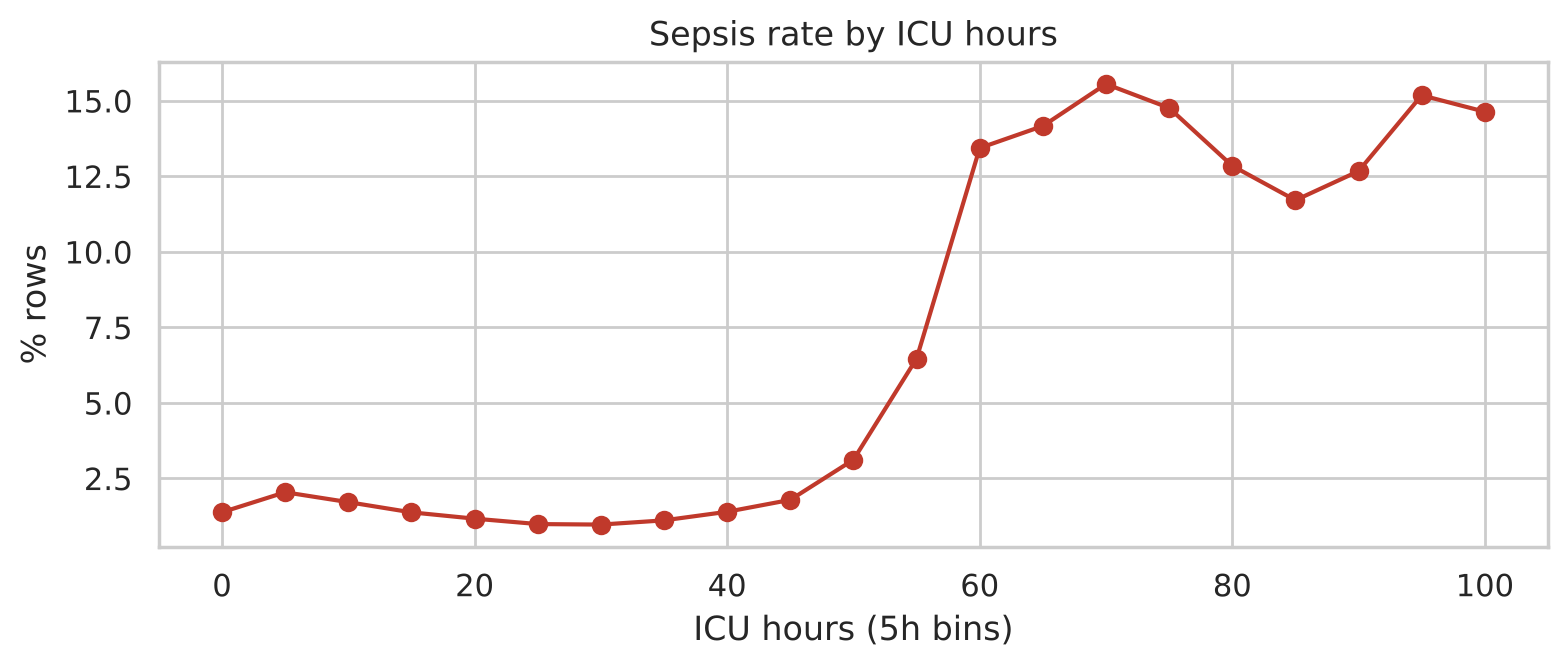

In [7]:
rate = clean.groupby(clean["ICULOS"].clip(upper=100) // 5 * 5)[C.TARGET].mean() * 100
ax = rate.plot(figsize=(8, 3.5), color="#c0392b", marker="o")
ax.set(title="Sepsis rate by ICU hours", xlabel="ICU hours (5h bins)", ylabel="% rows")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "eda_icu_hours.png", dpi=130); plt.show()

## 6. Final dataset summary

In [8]:
print(clean.groupby("split").agg(rows=(C.TARGET, "size"), sepsis_rate=(C.TARGET, "mean"),
                                  patients=(C.GROUP, "nunique")).round(4))
print("Missing values left in features:", int(clean[C.FEATURES].isna().sum().sum()),
      "(the model imputer fills them with train median)")

         rows  sepsis_rate  patients
split                               
test    80445       0.0202      2109
train  384548       0.0220      9839
val     81129       0.0217      2109


Missing values left in features: 783315 (the model imputer fills them with train median)
